# X Feature vs Y Target — Relationship Visualizations
**Dataset:** `data/splits/hri/model_v1/train.csv` · **Default Y:** `hri_score_0_100` (continuous HRI score)

This notebook creates **one graph per X feature**, correlation charts, and optional risk-class comparisons. It automatically handles numeric, binary, and categorical X columns. Identifiers, dataset split, and alternative target labels are excluded from X. Correlation describes association, **not causation**. Run all cells in order.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

sns.set_theme(style="whitegrid", context="notebook")
DATA_DIR = Path("/Users/keerthikeerthi/Desktop/J26-IT-359/components/habitat_risk/data/splits")
DATA_PATH = DATA_DIR / "hri" / "model_v1" / "train.csv"
assert DATA_PATH.exists(), f"CSV not found: {DATA_PATH}"
df = pd.read_csv(DATA_PATH, low_memory=False)
print(f"Loaded {len(df):,} rows and {len(df.columns)} columns")
display(df.head(3))

Loaded 24,752 rows and 33 columns


,cell_id,reference_year,dataset_split,climate__annual_mean_temperature_c,climate__annual_precipitation_mm,climate__temperature_c_anomaly,climate__temperature_c_trailing5_slope_per_year,climate__precipitation_mm_anomaly,climate__precipitation_mm_trailing5_slope_per_year,terrain__mean_elevation_m,...,quantile_risk_class,context__observed_checklist_locations,context__sampled_ndvi_mean,context__ndvi_valid_event_count,context__sampled_elevation_mean_m,context__survey_duration_mean_minutes,context__survey_distance_mean_km,context__sampled_land_cover_mode,context__bird_evidence_available,context__sampled_ndvi_missing
0,lka_laea_5000m_-10_-1,2010,train,0.776597,0.282989,0.480505,0.429949,0.527164,0.524089,0.047672,...,High,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0,1
1,lka_laea_5000m_-10_-12,2010,train,0.717720,0.404530,0.480505,0.429949,0.527164,0.524089,0.066682,...,Low,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0,1
2,lka_laea_5000m_-10_-13,2010,train,0.702525,0.424296,0.480505,0.429949,0.527164,0.524089,0.063003,...,Low,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0,1


## 1. Select the Y target and X columns
Change `TARGET` to `fixed_risk_class` or `quantile_risk_class` for categorical Y. The default selects all eligible predictors, including contextual variables; set `ONLY_CORE_FEATURES=True` to focus on the 9 climate/terrain predictors used in your earlier HRI models. Contextual features may be missing or unavailable at prediction time, so don't assume they are safe for training.

In [2]:
TARGET = "hri_score_0_100"  # alternatives: "fixed_risk_class", "quantile_risk_class"
ONLY_CORE_FEATURES = False
MAX_SCATTER_POINTS = 3000
RANDOM_STATE = 42
SAVE_FIGURES = True
OUT_DIR = Path("feature_target_graphs")
OUT_DIR.mkdir(exist_ok=True)

excluded = {"cell_id", "reference_year", "dataset_split", "hri_score_0_100", "fixed_risk_class", "quantile_risk_class"}
core = [c for c in df.columns if c.startswith(("climate__", "terrain__")) and not c.endswith("__was_missing")]
features = core if ONLY_CORE_FEATURES else [c for c in df.columns if c not in excluded]
assert TARGET in df.columns
assert features, "No X features found"
print("Y:", TARGET, "| X features:", len(features))
print("X columns:", *features, sep="\n • ")
print("Y missing:", df[TARGET].isna().sum())

Y: hri_score_0_100 | X features: 27
X columns:
 • climate__annual_mean_temperature_c
 • climate__annual_precipitation_mm
 • climate__temperature_c_anomaly
 • climate__temperature_c_trailing5_slope_per_year
 • climate__precipitation_mm_anomaly
 • climate__precipitation_mm_trailing5_slope_per_year
 • terrain__mean_elevation_m
 • terrain__elevation_sd_m
 • terrain__mean_slope_degrees
 • climate__annual_mean_temperature_c__was_missing
 • climate__annual_precipitation_mm__was_missing
 • climate__temperature_c_anomaly__was_missing
 • climate__temperature_c_trailing5_slope_per_year__was_missing
 • climate__precipitation_mm_anomaly__was_missing
 • climate__precipitation_mm_trailing5_slope_per_year__was_missing
 • terrain__mean_elevation_m__was_missing
 • terrain__elevation_sd_m__was_missing
 • terrain__mean_slope_degrees__was_missing
 • context__observed_checklist_locations
 • context__sampled_ndvi_mean
 • context__ndvi_valid_event_count
 • context__sampled_elevation_mean_m
 • context__survey_

## 2. One X-versus-Y graph for every feature
Numeric X vs numeric Y → scatter (or binary-group boxplot). Categorical X vs numeric Y → boxplot. Numeric X vs categorical Y → boxplot by class. Categorical X vs categorical Y → normalized stacked bar chart. Large scatterplots use a reproducible sample **only for visualization**.

[1/27] climate__annual_mean_temperature_c


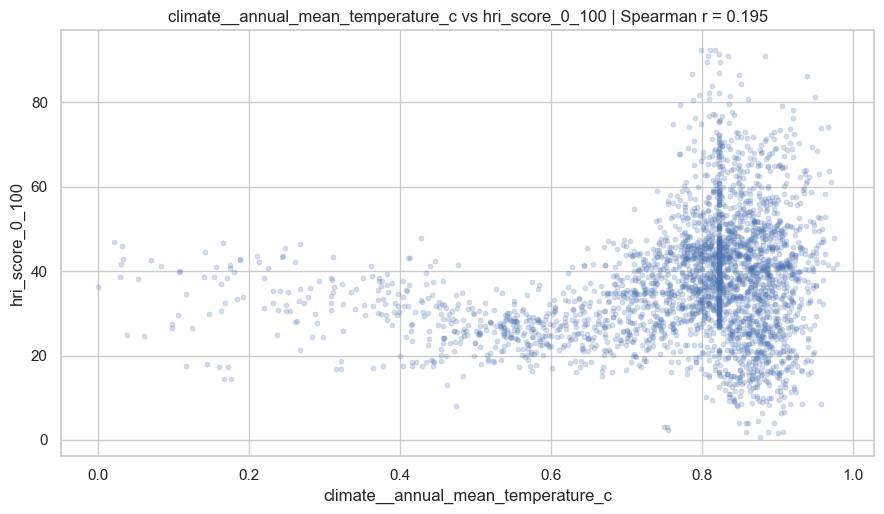

[2/27] climate__annual_precipitation_mm


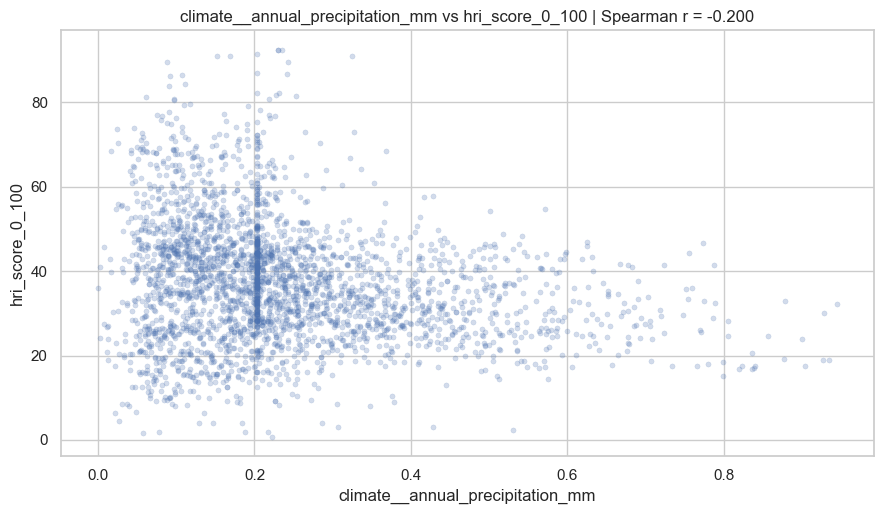

[3/27] climate__temperature_c_anomaly


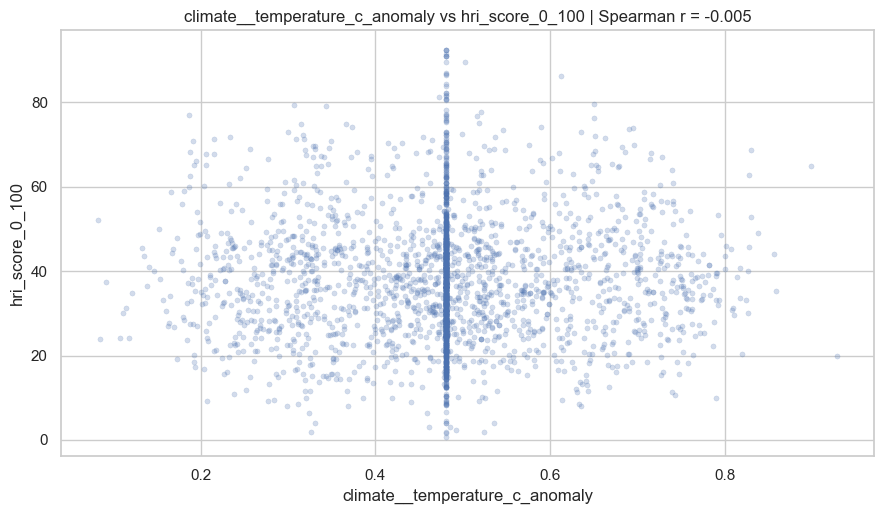

[4/27] climate__temperature_c_trailing5_slope_per_year


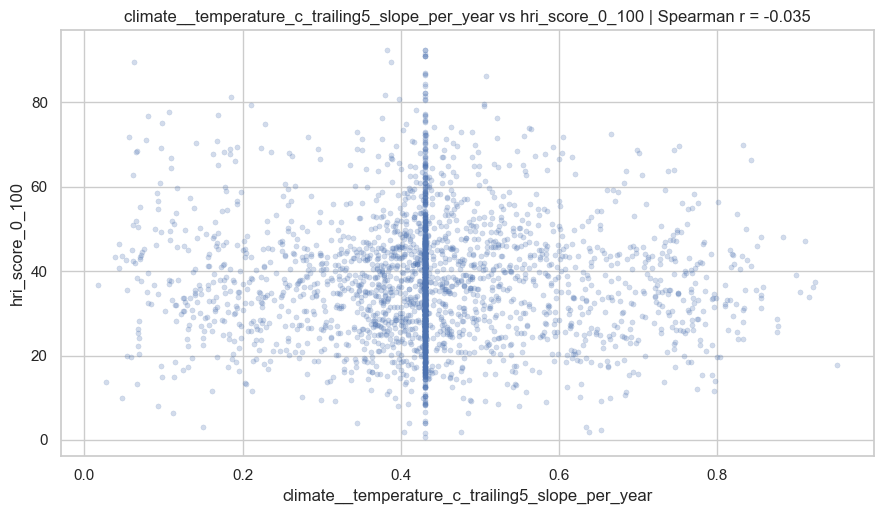

[5/27] climate__precipitation_mm_anomaly


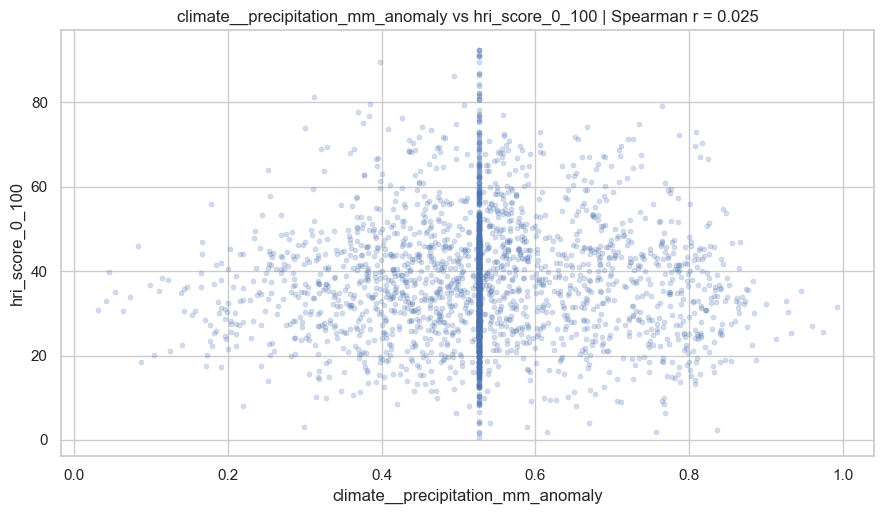

[6/27] climate__precipitation_mm_trailing5_slope_per_year


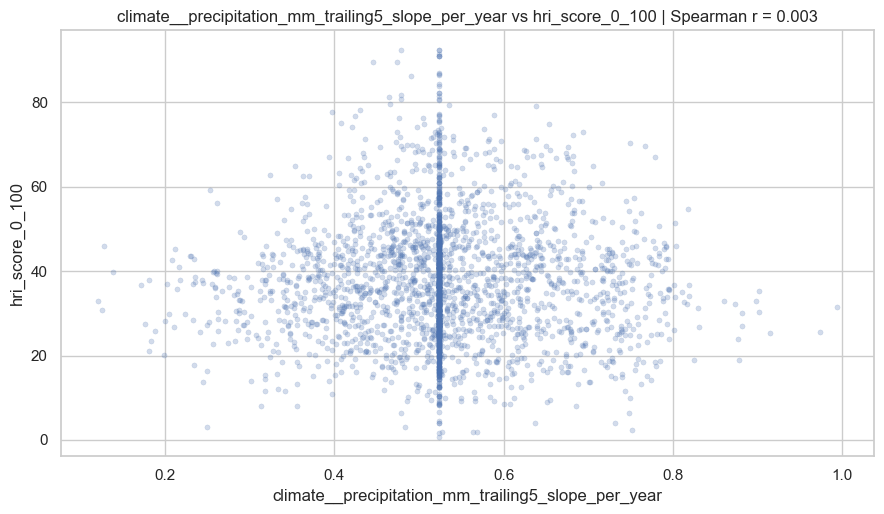

[7/27] terrain__mean_elevation_m


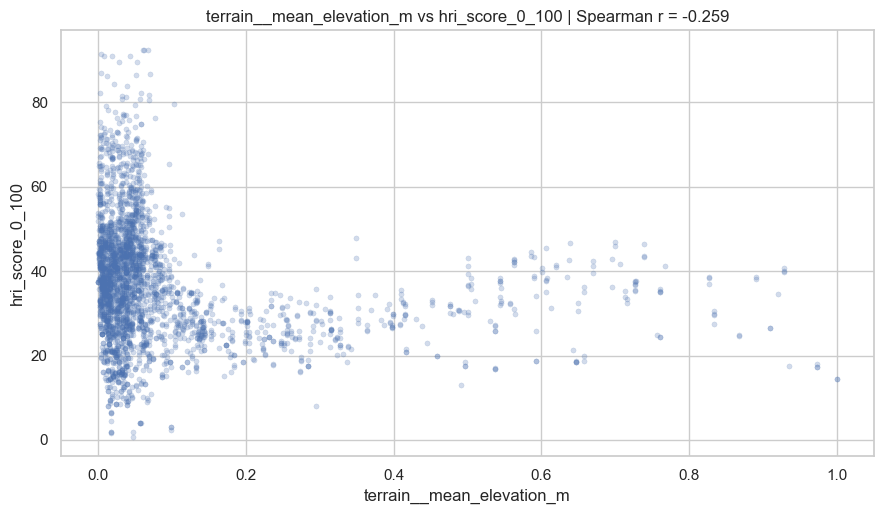

[8/27] terrain__elevation_sd_m


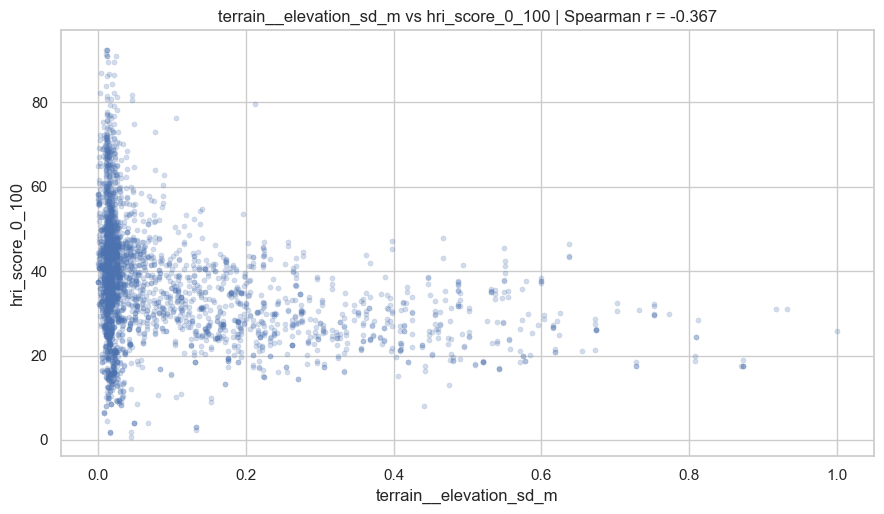

[9/27] terrain__mean_slope_degrees


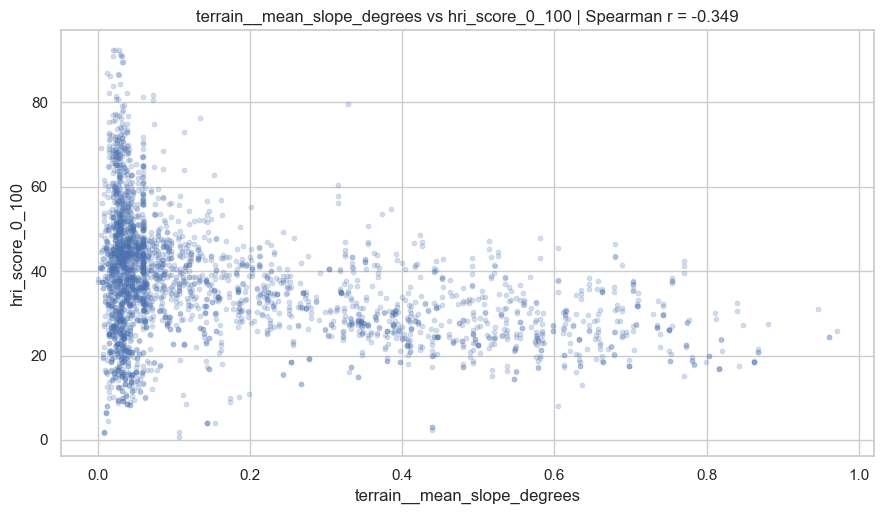

[10/27] climate__annual_mean_temperature_c__was_missing


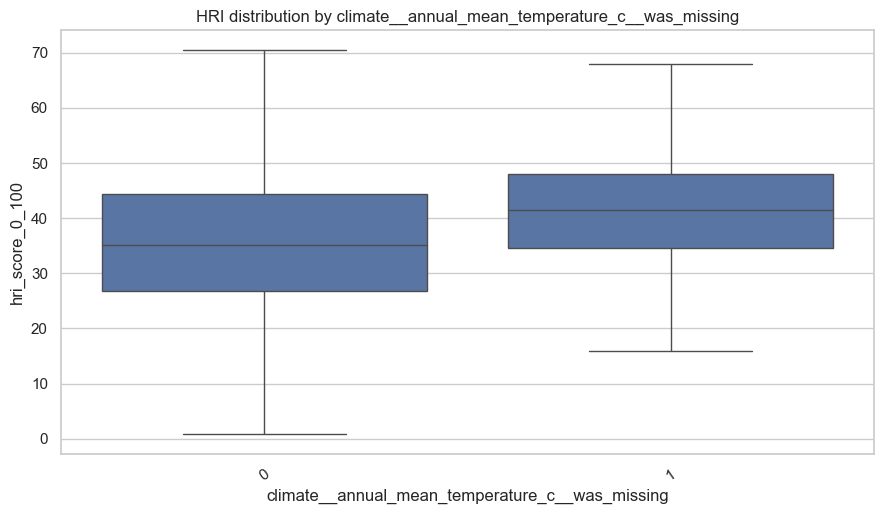

[11/27] climate__annual_precipitation_mm__was_missing


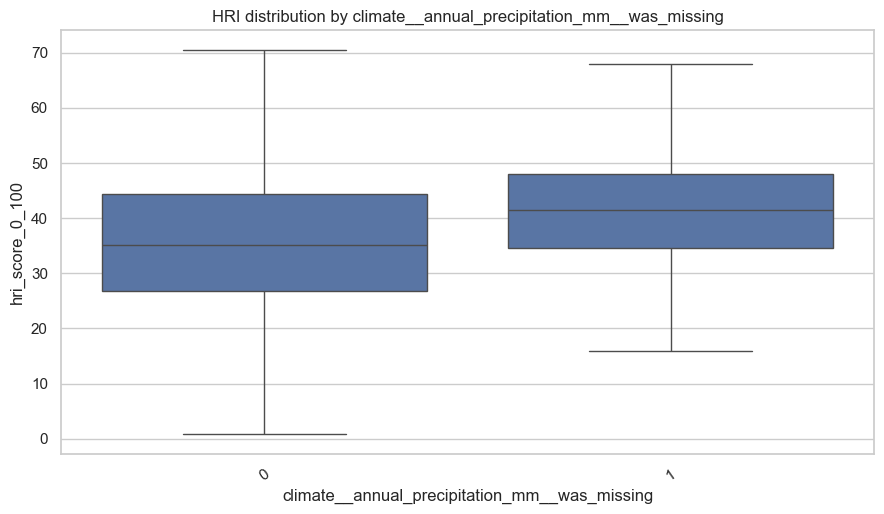

[12/27] climate__temperature_c_anomaly__was_missing


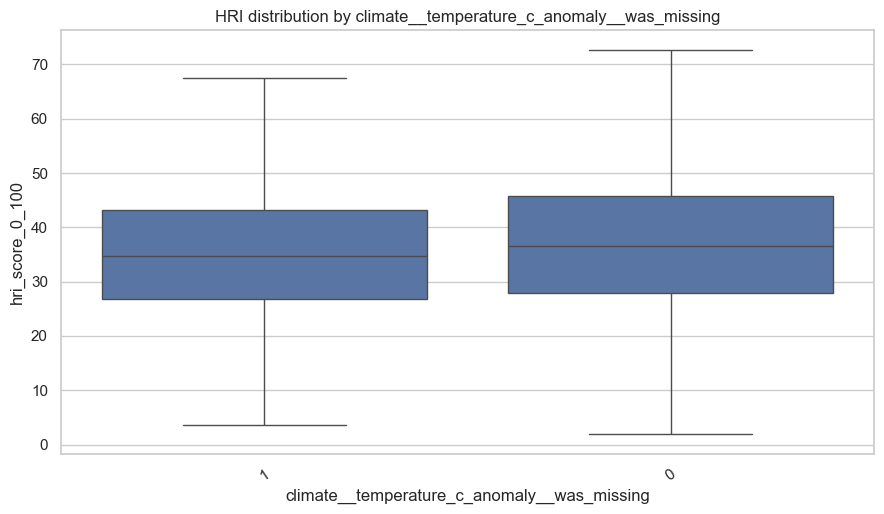

[13/27] climate__temperature_c_trailing5_slope_per_year__was_missing


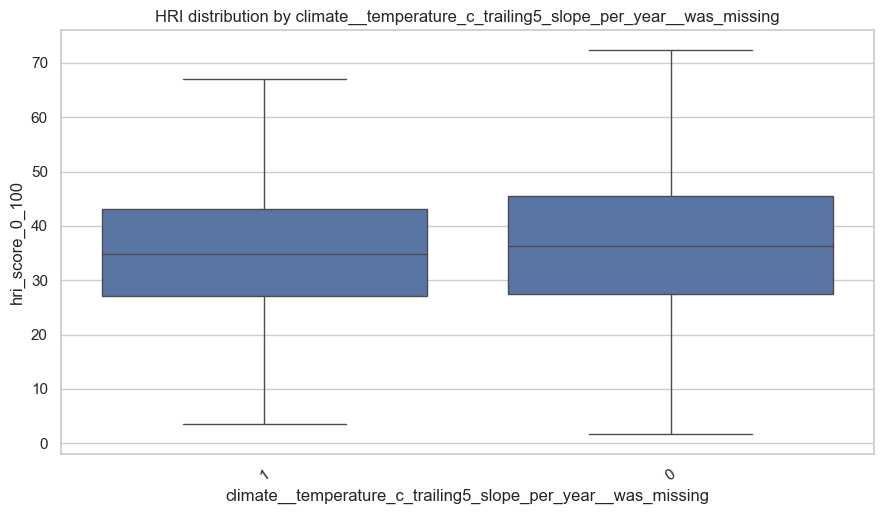

[14/27] climate__precipitation_mm_anomaly__was_missing


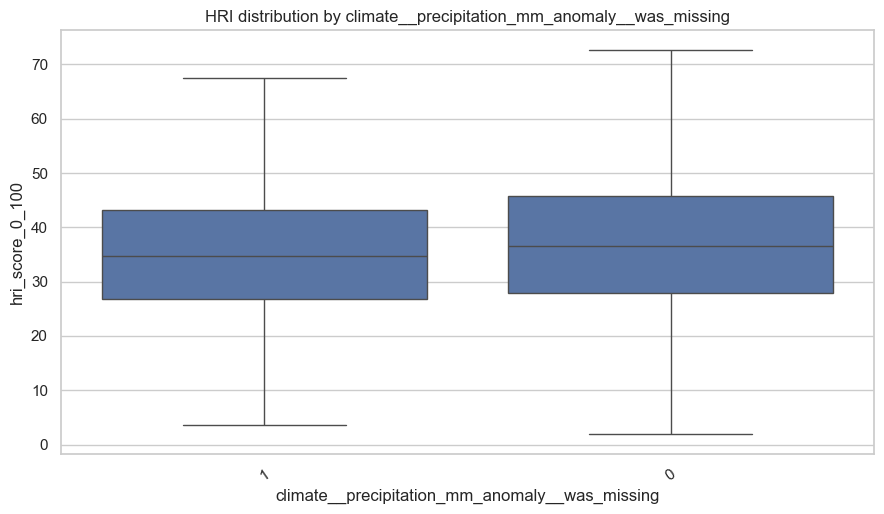

[15/27] climate__precipitation_mm_trailing5_slope_per_year__was_missing


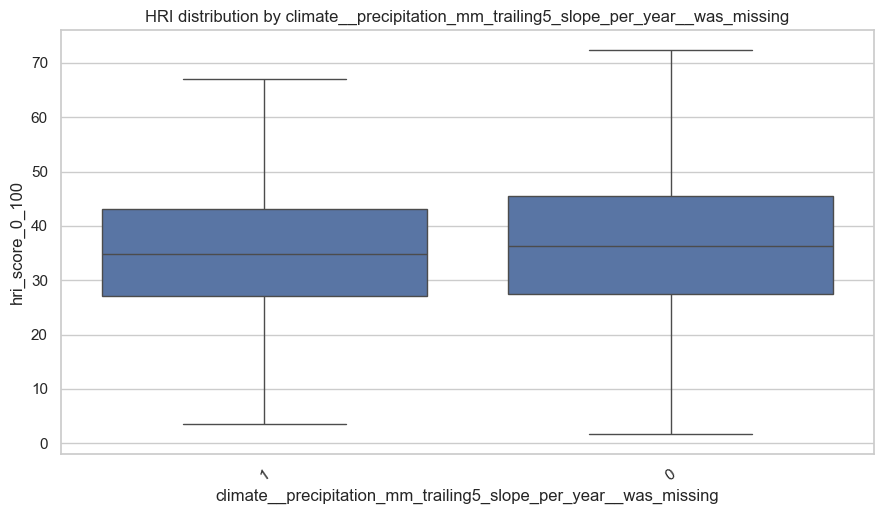

[16/27] terrain__mean_elevation_m__was_missing


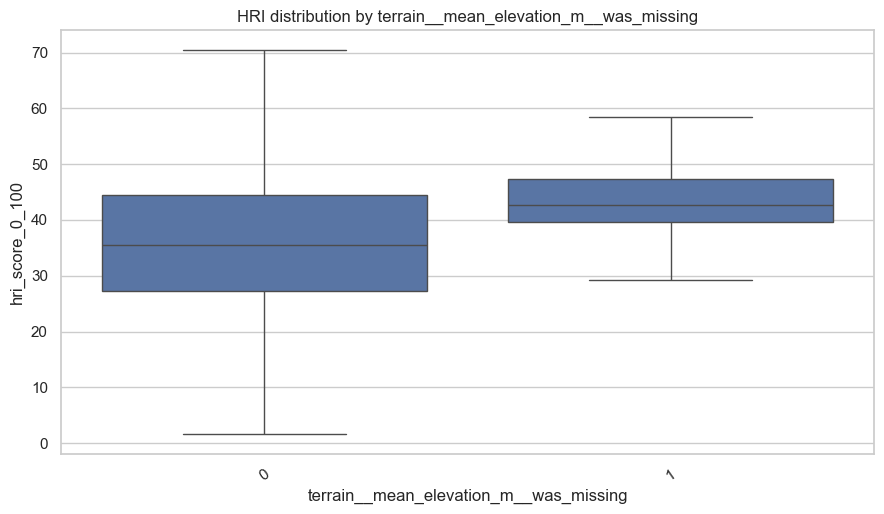

[17/27] terrain__elevation_sd_m__was_missing


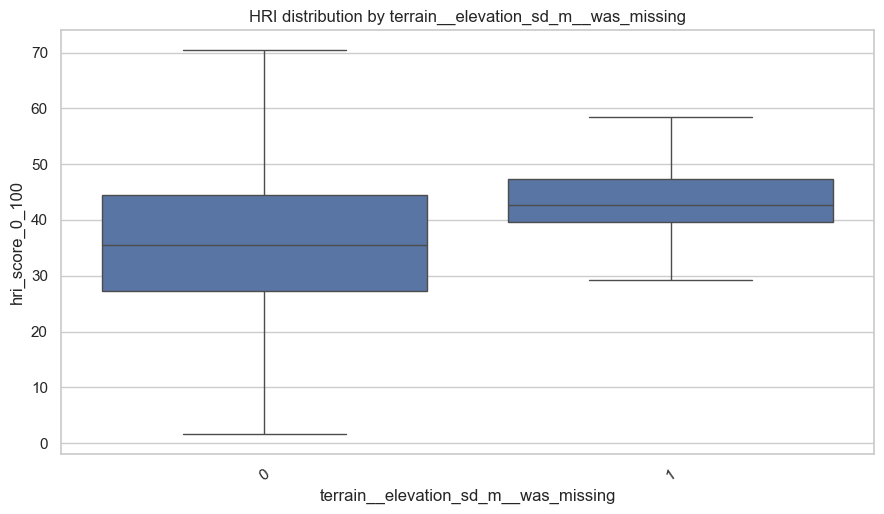

[18/27] terrain__mean_slope_degrees__was_missing


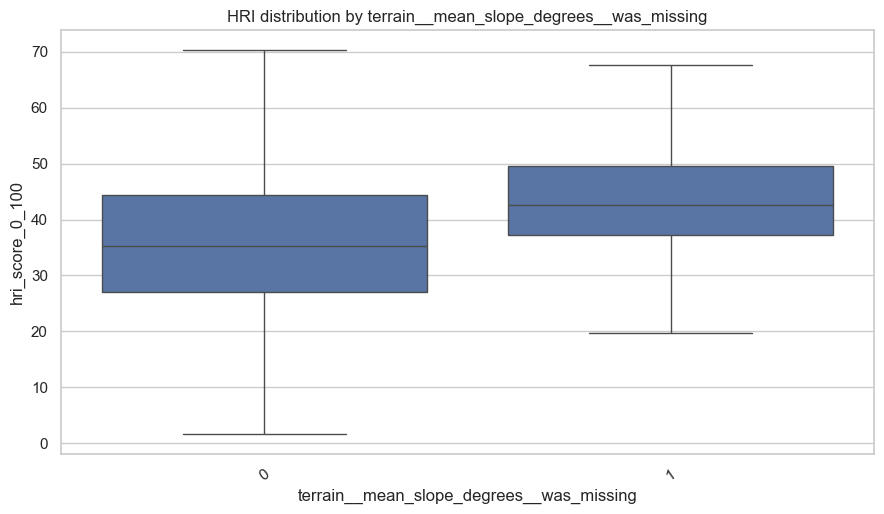

[19/27] context__observed_checklist_locations


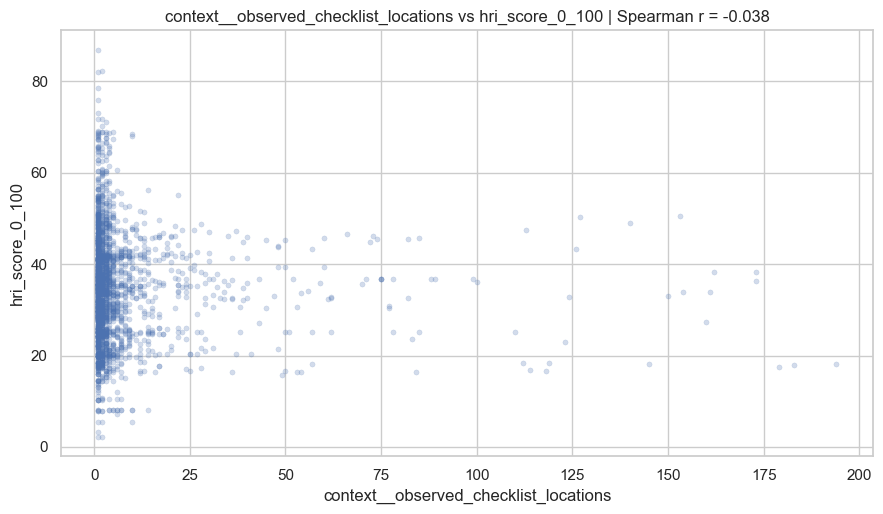

[20/27] context__sampled_ndvi_mean


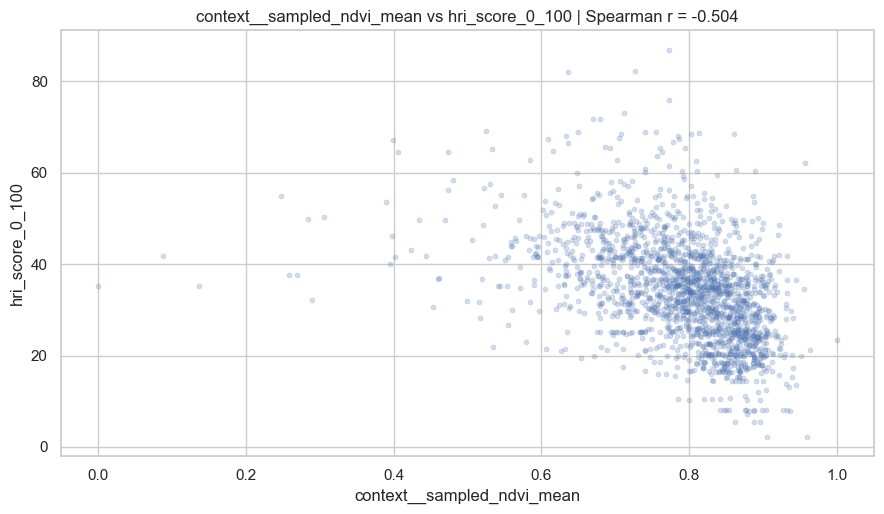

[21/27] context__ndvi_valid_event_count


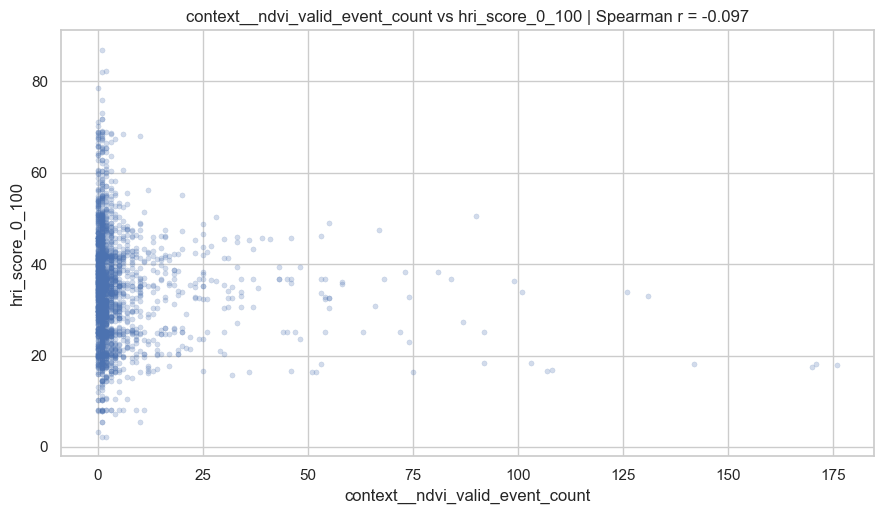

[22/27] context__sampled_elevation_mean_m


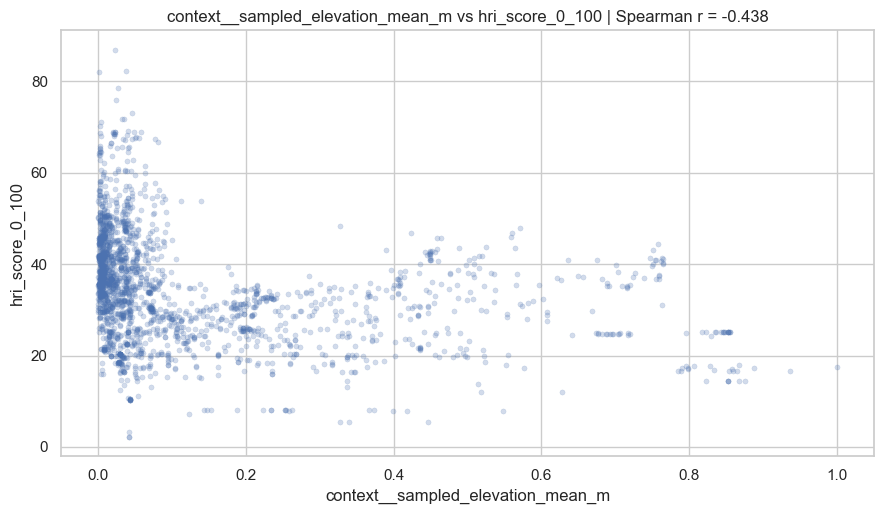

[23/27] context__survey_duration_mean_minutes


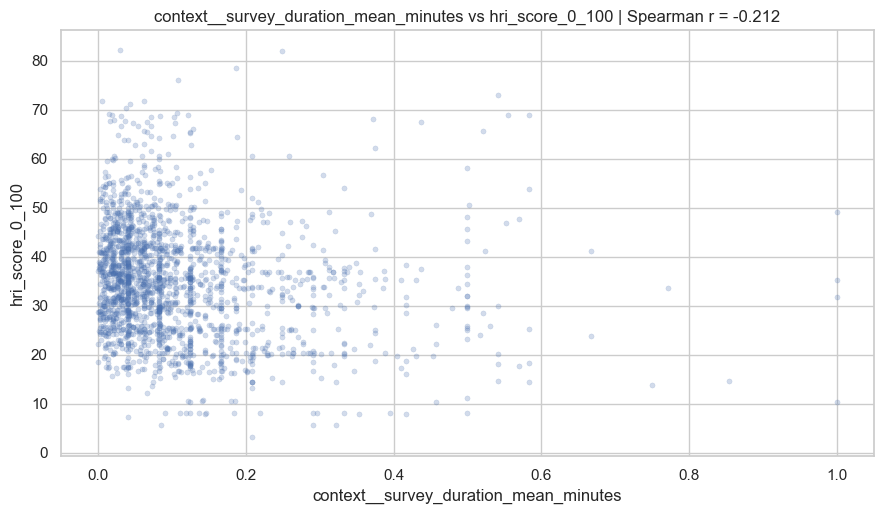

[24/27] context__survey_distance_mean_km


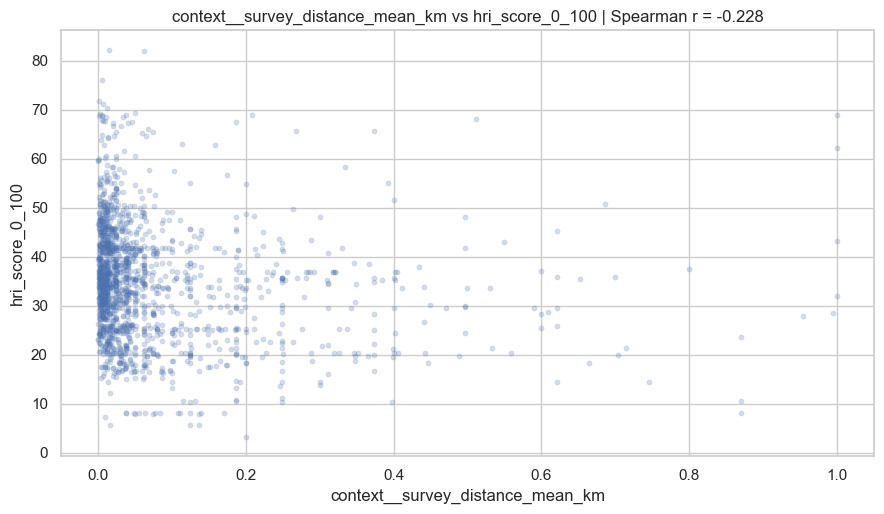

[25/27] context__sampled_land_cover_mode


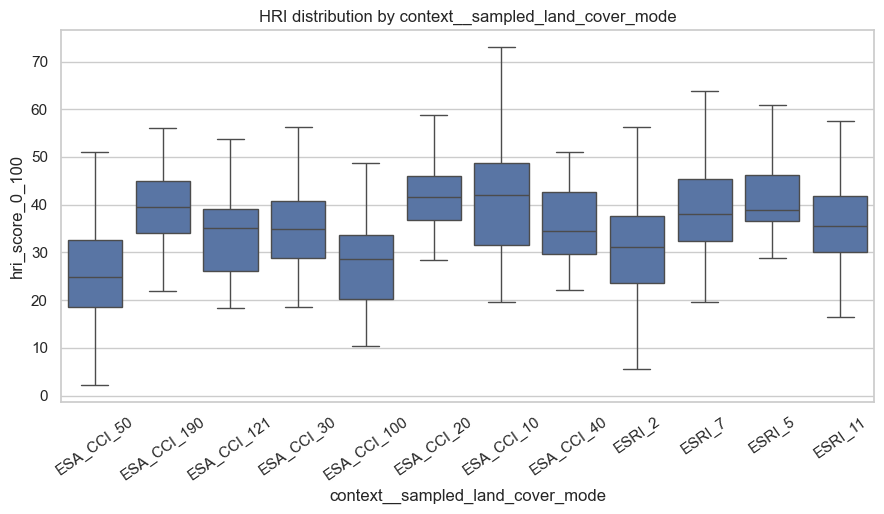

[26/27] context__bird_evidence_available


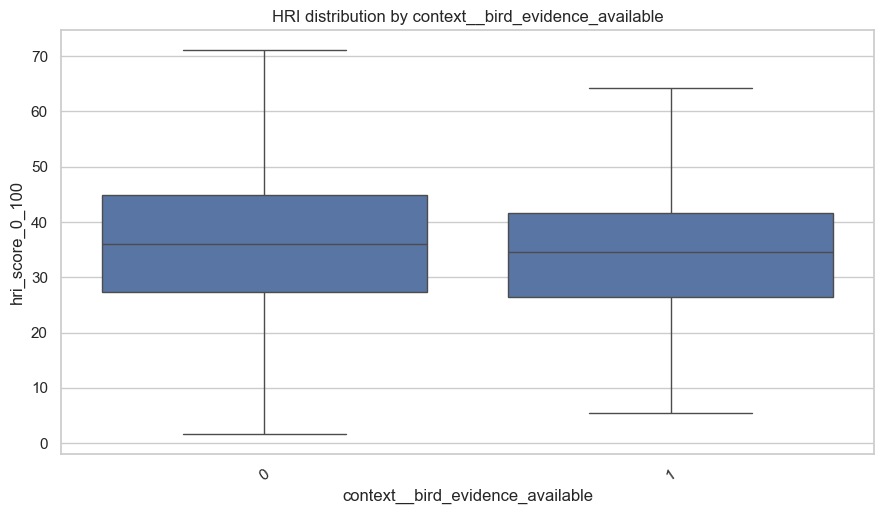

[27/27] context__sampled_ndvi_missing


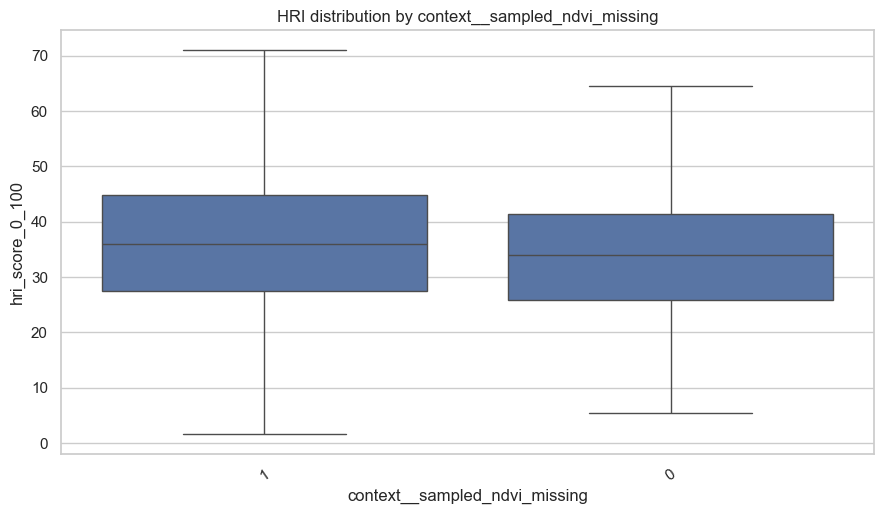

In [3]:
from pandas.api.types import is_numeric_dtype
import re

def plot_feature_vs_target(data, x, y, max_points=3000):
    tmp = data[[x, y]].replace([np.inf, -np.inf], np.nan).dropna()
    if tmp.empty:
        print(f"SKIP {x}: no nonmissing X/Y pairs")
        return
    x_num = is_numeric_dtype(tmp[x])
    y_num = is_numeric_dtype(tmp[y]) and y == "hri_score_0_100"
    x_low_card = tmp[x].nunique() <= 8
    if len(tmp) > max_points and x_num and y_num and not x_low_card:
        drawn = tmp.sample(max_points, random_state=RANDOM_STATE)
    else:
        drawn = tmp
    fig, ax = plt.subplots(figsize=(9, 5.3))
    if y_num and x_num and not x_low_card:
        sns.scatterplot(data=drawn, x=x, y=y, alpha=.25, s=14, ax=ax, edgecolor=None)
        corr = tmp[x].corr(tmp[y], method="spearman")
        ax.set_title(f"{x} vs {y} | Spearman r = {corr:.3f}")
    elif y_num:
        if x_num and x_low_card:
            drawn = drawn.copy(); drawn[x] = drawn[x].astype(str)
        cats = tmp[x].value_counts().index[:12]
        sns.boxplot(data=drawn[drawn[x].isin(cats)] if not x_num else drawn, x=x, y=y, ax=ax, showfliers=False)
        ax.set_title(f"HRI distribution by {x}")
        ax.tick_params(axis="x", labelrotation=35)
    elif x_num and not x_low_card:
        sns.boxplot(data=drawn, x=y, y=x, ax=ax, showfliers=False)
        ax.set_title(f"{x} by {y}")
        ax.tick_params(axis="x", labelrotation=30)
    else:
        counts = pd.crosstab(tmp[x].astype(str), tmp[y].astype(str), normalize="index")
        counts = counts.loc[tmp[x].astype(str).value_counts().head(12).index]
        counts.plot(kind="bar", stacked=True, ax=ax, colormap="tab20")
        ax.set_ylabel("Proportion within X category")
        ax.set_title(f"{x} vs {y} — class proportions")
        ax.legend(title=y, bbox_to_anchor=(1.02, 1), loc="upper left")
        ax.tick_params(axis="x", labelrotation=40)
    ax.set_xlabel(x)
    fig.tight_layout()
    if SAVE_FIGURES:
        safe = re.sub(r"[^A-Za-z0-9_-]", "_", x)
        fig.savefig(OUT_DIR / f"{safe}_vs_{y}.png", dpi=140, bbox_inches="tight")
    plt.show()
    plt.close(fig)

for i, feature in enumerate(features, 1):
    print(f"[{i}/{len(features)}] {feature}")
    plot_feature_vs_target(df, feature, TARGET, MAX_SCATTER_POINTS)

## 3. Ranked correlations (for numeric HRI target)
Pearson captures linear relationships; Spearman captures monotonic relationships. These are **univariate** associations, not model feature importance. Missingness flags and one-hot-like variables can also be included.

,feature,n,pearson,spearman
19,context__sampled_ndvi_mean,1851,-0.440874,-0.504090
21,context__sampled_elevation_mean_m,2285,-0.298740,-0.438461
7,terrain__elevation_sd_m,24752,-0.323155,-0.367442
8,terrain__mean_slope_degrees,24752,-0.360827,-0.348925
6,terrain__mean_elevation_m,24752,-0.207643,-0.259203
23,context__survey_distance_mean_km,1657,-0.143292,-0.228448
22,context__survey_duration_mean_minutes,2024,-0.167383,-0.212192
1,climate__annual_precipitation_mm,24752,-0.222071,-0.199776
0,climate__annual_mean_temperature_c,24752,0.222898,0.194874
17,terrain__mean_slope_degrees__was_missing,24752,0.121622,0.131531


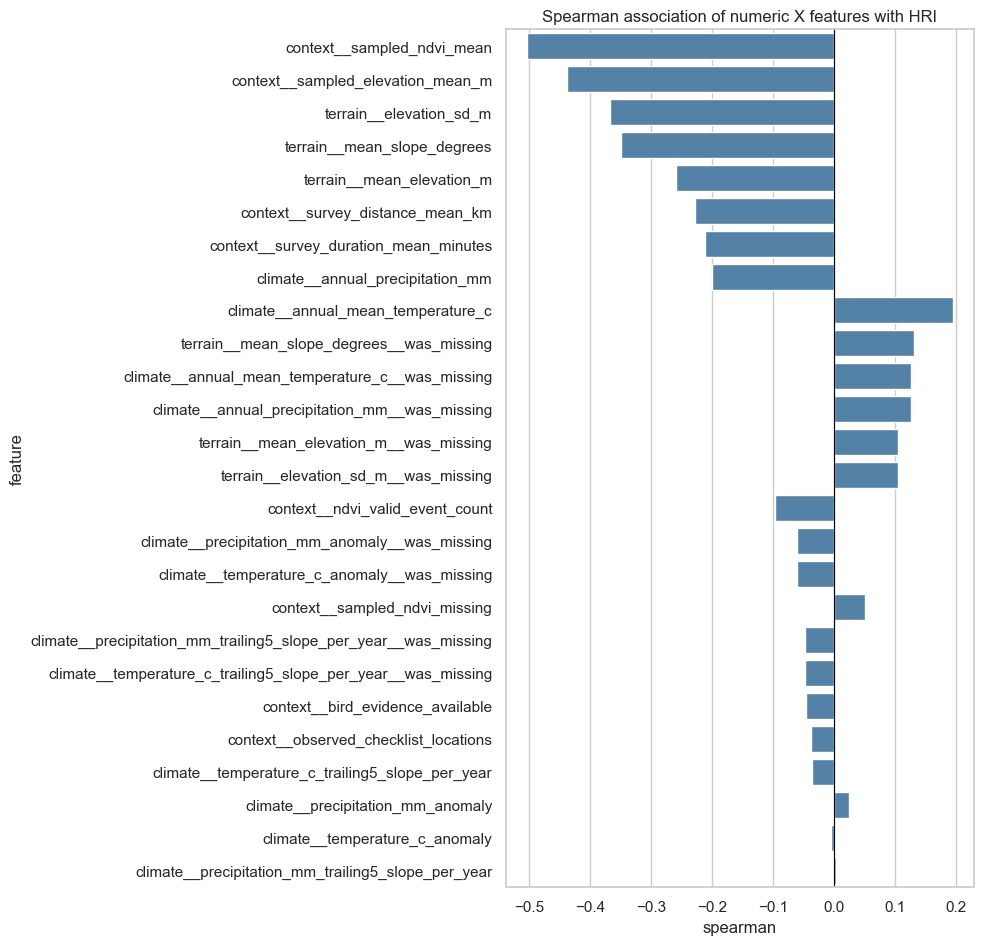

In [4]:
if TARGET == "hri_score_0_100":
    nums = [c for c in features if is_numeric_dtype(df[c]) and df[c].nunique(dropna=True) > 1]
    numeric_data = df[nums + [TARGET]].apply(pd.to_numeric, errors="coerce")
    rows = []
    for f in nums:
        pair = numeric_data[[f, TARGET]].replace([np.inf, -np.inf], np.nan).dropna()
        if len(pair) >= 3 and pair[f].nunique() > 1 and pair[TARGET].nunique() > 1:
            rows.append({"feature":f, "n":len(pair), "pearson":pair[f].corr(pair[TARGET]), "spearman":pair[f].corr(pair[TARGET], method="spearman")})
    corr_table = pd.DataFrame(rows)
    if not corr_table.empty:
        corr_table = corr_table.assign(abs_spearman=lambda t:t.spearman.abs()).sort_values("abs_spearman", ascending=False)
        display(corr_table.drop(columns="abs_spearman"))
        corr_table.drop(columns="abs_spearman").to_csv(OUT_DIR / "correlations_with_hri.csv", index=False)
        fig, ax = plt.subplots(figsize=(10, max(5, len(corr_table)*.37)))
        sns.barplot(data=corr_table, x="spearman", y="feature", ax=ax, color="steelblue")
        ax.axvline(0, color="black", lw=.8)
        ax.set_title("Spearman association of numeric X features with HRI")
        fig.tight_layout()
        if SAVE_FIGURES: fig.savefig(OUT_DIR / "spearman_ranked.png", dpi=160, bbox_inches="tight")
        plt.show()
else:
    print("Correlation ranking is for numeric HRI only; switch TARGET to hri_score_0_100.")

## 4. Numeric correlation heatmap

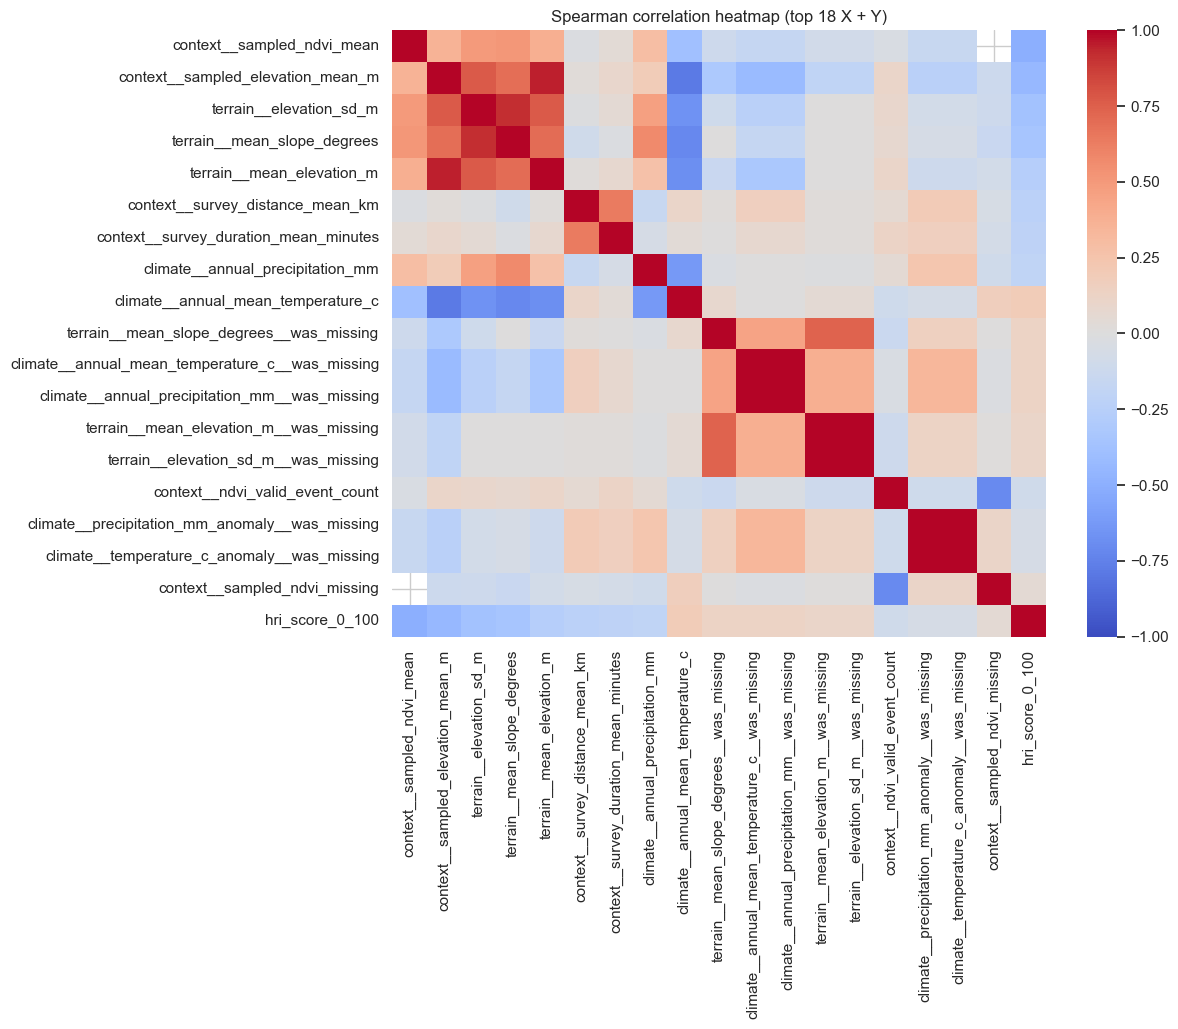

In [5]:
if TARGET == "hri_score_0_100" and nums:
    ordered = corr_table["feature"].head(18).tolist() + [TARGET] if not corr_table.empty else [TARGET]
    fig, ax = plt.subplots(figsize=(max(8, len(ordered)*.65), max(6, len(ordered)*.55)))
    sns.heatmap(numeric_data[ordered].corr(method="spearman"), cmap="coolwarm", center=0, vmin=-1, vmax=1, ax=ax)
    ax.set_title("Spearman correlation heatmap (top 18 X + Y)")
    fig.tight_layout()
    if SAVE_FIGURES: fig.savefig(OUT_DIR / "correlation_heatmap.png", dpi=150, bbox_inches="tight")
    plt.show()

## 5. Summary and export
The PNG files and correlation CSV are saved to `feature_target_graphs/`. For your report, explain both direction and strength, and remember that low pairwise correlation does **not** rule out nonlinear or interacting effects. If you train HRI models, use your established spatial/temporal validation to test generalization.

In [6]:
print("Graphs saved in:", OUT_DIR.resolve())
print("Total PNG files:", len(list(OUT_DIR.glob("*.png"))))
print("Target counts / summary:")
print(df[TARGET].describe(include="all"))

Graphs saved in: /Users/keerthikeerthi/Desktop/J26-IT-359/components/habitat_risk/notebooks/hri/feature_target_graphs
Total PNG files: 29
Target counts / summary:
count    24752.000000
mean        37.042325
std         14.326639
min          0.793036
25%         27.360073
50%         35.769426
75%         44.626012
max         93.502631
Name: hri_score_0_100, dtype: float64
